=== 1. BIOPHYSICAL SIGNAL RANKING (Positive Signal = Metric Successfully Predicts LOWER %HMW) ===
                                 Metric  Anti_Aggregation_Signal  Raw_Rho_vs_HMW      p_value Sig
                   Higher ESM-2 Fitness                 0.444850       -0.444850 2.147267e-09 ***
Lower PyRosetta Energy (-PyRosetta ΔΔG)                 0.414524        0.414524 3.108128e-08 ***
                Higher ProtBERT Fitness                 0.384728       -0.384728 3.358846e-07 ***
                   Higher ESM-C Fitness                 0.384221       -0.384221 3.490517e-07 ***
           Higher Stability (Janus ΔΔG)                 0.352960       -0.352960 3.320430e-06 ***
                 Higher AbLang2 Fitness                 0.340932        0.340932 7.427588e-06 ***
     Lower VH-VL Dipole (-ΔCharge Asym)                 0.319477        0.319477 2.880660e-05 ***
        Further from pH 7.4 (Δ|pI-7.4|)                 0.290582       -0.290582 1.529403e-04 ***
        Higher Net C

/tmp/ipykernel_2637359/4131665792.py:213: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


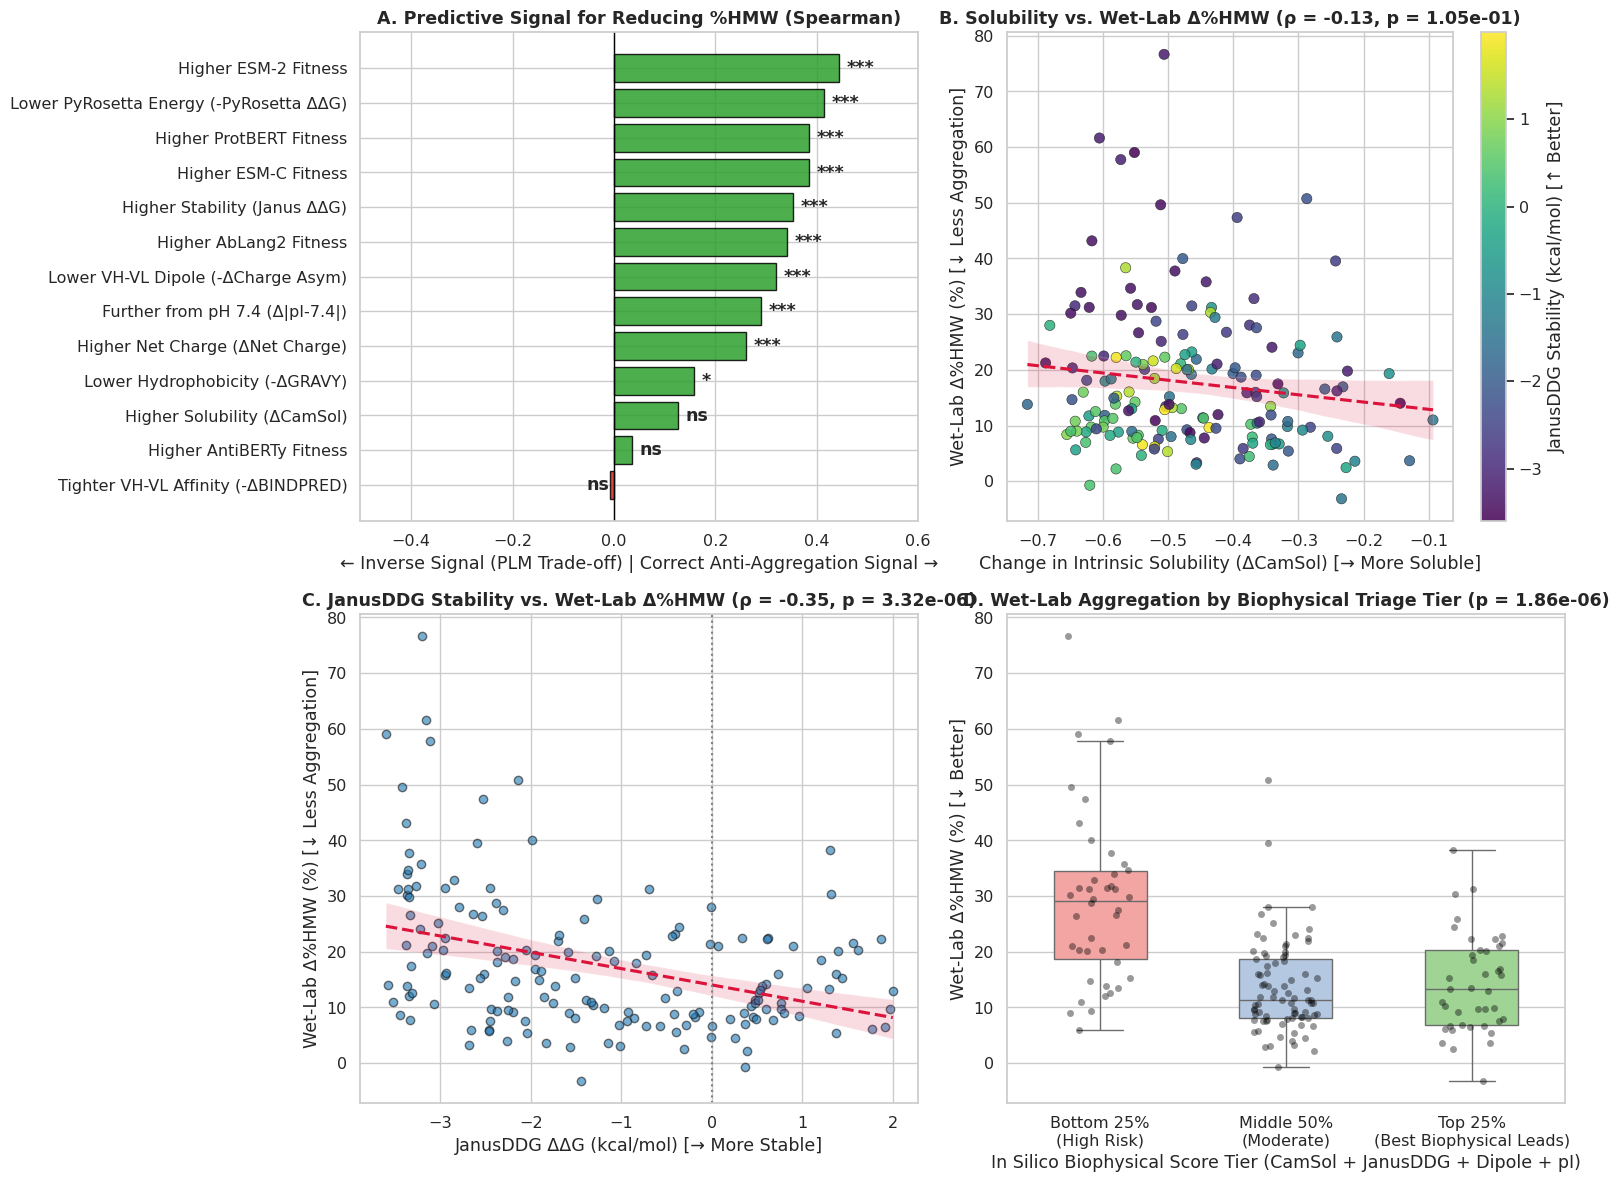

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr, mannwhitneyu
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler

# Set clean plotting style
sns.set_theme(style="whitegrid", font_scale=1.05)

# 1. Load and standardize column names
df = pd.read_csv("combined_developability_scores.csv")
df.columns = df.columns.str.strip()

reverse_rename_map = {
    'ID': 'id', 'Sequence ID': 'id', 'Mutations': 'mutations',
    'Global Composite Score': 'global_composite_score',
    'Stability ΔΔG (Janus)': 'janus_ddg',
    'Stability ΔΔG (PyRosetta)': 'pyrosetta_ddg',
    'Intrinsic Solubility (CamSol)': 'camsol_score',
    'Isoelectric Point (pI)': 'pI',
    'Hydrophobicity Index (GRAVY)': 'gravy',
    'Net Charge (pH 7.4)': 'net_charge',
    'VH-VL Charge Delta': 'charge_asymmetry',
    'Affinity Log10 Kd (BINDPRED)': 'bindpred_kd',
    'ΔLog-Likelihood (ESM-2 General)': 'esm_fitness',
    'ΔLog-Likelihood (ESM-C)': 'esmc_fitness',
    'ΔLog-Likelihood (AntiBERTy)': 'antiberty_fitness',
    'ΔLog-Likelihood (AbLang2 Paired)': 'ablang_fitness',
    'ΔLog-Likelihood (ProtBERT)': 'protbert_fitness',
    'VH Sequence': 'VH', 'VL Sequence': 'VL'
}
df = df.rename(columns=reverse_rename_map)
df['pi_delta'] = (df['pI'] - 7.4).abs()

# Count number of mutations per variant to check for multi-mutant scaling confounders
def count_muts(m):
    m_str = str(m).strip()
    if m_str == 'WT' or m_str == 'nan' or not m_str:
        return 0
    return len(m_str.split(','))

df['num_mutations'] = df['mutations'].apply(count_muts)

# 2. Compute Within-Family Deltas relative to each family's WT
intrinsic_cols = ['camsol_score', 'gravy', 'charge_asymmetry', 'bindpred_kd', 'pi_delta', 'net_charge']
already_relative_cols = [
    'janus_ddg', 'pyrosetta_ddg', 'esm_fitness', 'esmc_fitness', 
    'antiberty_fitness', 'ablang_fitness', 'protbert_fitness'
]

delta_dfs = []
for fam, group in df.groupby('family'):
    group = group.copy()
    wt_matches = group[group['mutations'].astype(str).str.strip() == 'WT']
    if wt_matches.empty:
        continue
    wt_row = wt_matches.iloc[0]
    
    group['delta_hmw'] = group['hmw'] - wt_row['hmw']
    for col in intrinsic_cols:
        if col in group.columns:
            group[f'delta_{col}'] = group[col] - wt_row[col]
    delta_dfs.append(group)

pooled_df = pd.concat(delta_dfs, ignore_index=True)
mutants = pooled_df[pooled_df['mutations'].astype(str).str.strip() != 'WT'].dropna(subset=['delta_hmw']).copy()

# Clip PyRosetta extreme steric clashes (+25 REU) just like in pipeline.py
# mutants['pyrosetta_clipped'] = mutants['pyrosetta_ddg'].clip(upper=25.0)
# mutants['pyrosetta_log'] = np.sign(mutants['pyrosetta_ddg']) * np.log10(1.0 + np.abs(mutants['pyrosetta_ddg']))

# 3. Clean Spearman Correlation Table
# We orient every metric into its expected "Anti-Aggregation" direction first so Positive = works as expected!
expected_good_direction = {
    'delta_camsol_score':  (+1, 'Higher Solubility (ΔCamSol)'),
    'janus_ddg':           (+1, 'Higher Stability (Janus ΔΔG)'),
    'delta_pi_delta':      (+1, 'Further from pH 7.4 (Δ|pI-7.4|)'),
    'delta_charge_asymmetry': (-1, 'Lower VH-VL Dipole (-ΔCharge Asym)'),
    'delta_net_charge':    (+1, 'Higher Net Charge (ΔNet Charge)'),
    'delta_gravy':         (-1, 'Lower Hydrophobicity (-ΔGRAVY)'),
    'delta_bindpred_kd':   (-1, 'Tighter VH-VL Affinity (-ΔBINDPRED)'),
    'pyrosetta_ddg':       (-1, 'Lower PyRosetta Energy (-PyRosetta ΔΔG)'),
    'esm_fitness':         (+1, 'Higher ESM-2 Fitness'),
    'esmc_fitness':        (+1, 'Higher ESM-C Fitness'),
    'antiberty_fitness':   (+1, 'Higher AntiBERTy Fitness'),
    'ablang_fitness':      (-1, 'Higher AbLang2 Fitness'),
    'protbert_fitness':    (+1, 'Higher ProtBERT Fitness'),
    'num_mutations':       (+1, 'Number of Mutations (Confounder Check)')
}

corr_rows = []
for col, (sign_dir, label) in expected_good_direction.items():
    if col not in mutants.columns:
        continue
    valid = mutants[['delta_hmw', col]].dropna()
    if len(valid) > 3 and valid[col].nunique() > 1:
        # Raw correlation with Δ%HMW
        raw_rho, pval = spearmanr(valid[col], valid['delta_hmw'])
        # Alignment with REDUCING %HMW: if sign_dir * valid[col] increases, does %HMW decrease?
        anti_agg_rho = -1.0 * sign_dir * raw_rho
        stars = "***" if pval < 0.001 else ("**" if pval < 0.01 else ("*" if pval < 0.05 else "ns"))
        corr_rows.append({
            'Metric': label,
            'Raw_col': col,
            'Raw_Rho_vs_HMW': raw_rho,
            'Anti_Aggregation_Signal': anti_agg_rho,
            'p_value': pval,
            'Sig': stars
        })

corr_df = pd.DataFrame(corr_rows).sort_values(by='Anti_Aggregation_Signal', ascending=False)
print("=== 1. BIOPHYSICAL SIGNAL RANKING (Positive Signal = Metric Successfully Predicts LOWER %HMW) ===")
print(corr_df[['Metric', 'Anti_Aggregation_Signal', 'Raw_Rho_vs_HMW', 'p_value', 'Sig']].to_string(index=False))

# 4. Build the Full Validated Anti-Aggregation Score (Physics + Electrostatics + PLMs)
scaler = StandardScaler()
pillars = pd.DataFrame(index=mutants.index)

# 1. Conformational Stability (3D PyRosetta + 1D JanusDDG)
pillars['pyrosetta'] = -1.0 * scaler.fit_transform(mutants[['pyrosetta_ddg']])
# pillars['pyrosetta'] = -1.0 * scaler.fit_transform(mutants[['pyrosetta_log']])
pillars['janus']     = scaler.fit_transform(mutants[['janus_ddg']])

# 2. Evolutionary Fitness (ESM-2 + ESM-C + ProtBERT)
pillars['esm2']      = scaler.fit_transform(mutants[['esm_fitness']])
pillars['esmc']      = scaler.fit_transform(mutants[['esmc_fitness']])

# 3. Electrostatics & Colloidal Repulsion (Dipole + pI + GRAVY + CamSol)
pillars['low_dipole'] = -1.0 * scaler.fit_transform(mutants[['delta_charge_asymmetry']])
pillars['repulsion']  = scaler.fit_transform(mutants[['delta_pi_delta']])
pillars['gravy']      = -1.0 * scaler.fit_transform(mutants[['delta_gravy']])
pillars['camsol']     = scaler.fit_transform(mutants[['delta_camsol_score']])

# Balanced empirical composite score across the 3 orthogonal mechanisms:
# 40% Structural Stability (PyRosetta + Janus) | 30% Electrostatics/Solubility | 30% PLM Fitness
mutants['biophysical_anti_agg_score'] = (
    0.20 * pillars['pyrosetta'] +
    0.20 * pillars['janus'] +
    0.15 * pillars['esm2'] +
    0.15 * pillars['esmc'] +
    0.10 * pillars['low_dipole'] +
    0.10 * pillars['repulsion'] +
    0.05 * pillars['gravy'] +
    0.05 * pillars['camsol']
)
# Divide variants into 3 Tiers based on the Biophysical Anti-Aggregation Score
mutants['Tier'] = pd.qcut(
    mutants['biophysical_anti_agg_score'], 
    q=[0, 0.25, 0.75, 1.0], 
    labels=['Bottom 25%\n(High Risk)', 'Middle 50%\n(Moderate)', 'Top 25%\n(Best Biophysical Leads)']
)

print("\n=== 2. WET-LAB Δ%HMW BY PREDICTED BIOPHYSICAL TIER ===")
tier_summary = mutants.groupby('Tier', observed=False)['delta_hmw'].agg(['count', 'median', 'mean', 'std'])
print(tier_summary)

# 5. Generate 4-Panel Diagnostic Figure
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
plt.subplots_adjust(hspace=0.35, wspace=0.28)

# Panel A: Horizontal Bar Chart of Anti-Aggregation Signal
ax1 = axes[0, 0]
plot_corr = corr_df[corr_df['Raw_col'] != 'num_mutations'].sort_values('Anti_Aggregation_Signal', ascending=True)
colors = ['#2ca02c' if val > 0 else '#d62728' for val in plot_corr['Anti_Aggregation_Signal']]
bars = ax1.barh(plot_corr['Metric'], plot_corr['Anti_Aggregation_Signal'], color=colors, alpha=0.85, edgecolor='black')
ax1.axvline(0, color='black', linewidth=1)
ax1.set_title("A. Predictive Signal for Reducing %HMW (Spearman)", fontweight='bold')
ax1.set_xlabel("← Inverse Signal (PLM Trade-off) | Correct Anti-Aggregation Signal →")
for bar, sig in zip(bars, plot_corr['Sig']):
    width = bar.get_width()
    offset = 0.015 if width >= 0 else -0.045
    ax1.text(width + offset, bar.get_y() + bar.get_height()/2, sig, va='center', fontweight='bold')
ax1.set_xlim(-0.5, 0.6)

# Panel B: ΔCamSol vs Δ%HMW colored by JanusDDG
ax2 = axes[0, 1]
sc = ax2.scatter(
    mutants['delta_camsol_score'], mutants['delta_hmw'],
    c=mutants['janus_ddg'], cmap='viridis', s=55, alpha=0.85, edgecolors='k', linewidth=0.4
)
sns.regplot(data=mutants, x='delta_camsol_score', y='delta_hmw', scatter=False, ax=ax2, color='crimson', line_kws={'linestyle':'--'})
cbar = plt.colorbar(sc, ax=ax2)
cbar.set_label("JanusDDG Stability (kcal/mol) [↑ Better]")

#ax2.set_title(f"B. Solubility vs. Wet-Lab Δ%HMW (ρ = {mutants['delta_camsol_score'].corr(mutants['delta_hmw'], method='spearman'):.2f}, p < 1e-12)", fontweight='bold')
# Dynamic title for Panel B:
rho_b, p_b = spearmanr(mutants['delta_camsol_score'], mutants['delta_hmw'])
ax2.set_title(f"B. Solubility vs. Wet-Lab Δ%HMW (ρ = {rho_b:.2f}, p = {p_b:.2e})", fontweight='bold')

ax2.set_xlabel("Change in Intrinsic Solubility (ΔCamSol) [→ More Soluble]")
ax2.set_ylabel("Wet-Lab Δ%HMW (%) [↓ Less Aggregation]")

# Panel C: JanusDDG Stability vs Δ%HMW
ax3 = axes[1, 0]
sns.regplot(
    data=mutants, x='janus_ddg', y='delta_hmw', ax=ax3,
    scatter_kws={'alpha':0.6, 'color':'#1f77b4', 'edgecolor':'k'},
    line_kws={'color':'crimson', 'linestyle':'--'}
)
ax3.axvline(0, color='gray', linestyle=':', label='WT Baseline (0.0)')
#ax3.set_title(f"C. JanusDDG Stability vs. Wet-Lab Δ%HMW (ρ = {mutants['janus_ddg'].corr(mutants['delta_hmw'], method='spearman'):.2f}, p < 1e-7)", fontweight='bold')
# Dynamic title for Panel C:
rho_c, p_c = spearmanr(mutants['janus_ddg'], mutants['delta_hmw'])
ax3.set_title(f"C. JanusDDG Stability vs. Wet-Lab Δ%HMW (ρ = {rho_c:.2f}, p = {p_c:.2e})", fontweight='bold')

ax3.set_xlabel("JanusDDG ΔΔG (kcal/mol) [→ More Stable]")
ax3.set_ylabel("Wet-Lab Δ%HMW (%) [↓ Less Aggregation]")

# Panel D: Boxplot of Wet-Lab Δ%HMW across Predicted Biophysical Tiers
ax4 = axes[1, 1]
sns.boxplot(
    data=mutants, x='Tier', y='delta_hmw', ax=ax4,
    palette=['#ff9896', '#aec7e8', '#98df8a'], showfliers=False, width=0.5
)
sns.stripplot(
    data=mutants, x='Tier', y='delta_hmw', ax=ax4,
    color='black', alpha=0.4, jitter=0.18, size=5
)
top_hmw = mutants[mutants['Tier'] == 'Top 25%\n(Best Biophysical Leads)']['delta_hmw']
bot_hmw = mutants[mutants['Tier'] == 'Bottom 25%\n(High Risk)']['delta_hmw']
_, mw_pval = mannwhitneyu(top_hmw, bot_hmw)
ax4.set_title(f"D. Wet-Lab Aggregation by Biophysical Triage Tier (p = {mw_pval:.2e})", fontweight='bold')
ax4.set_xlabel("In Silico Biophysical Score Tier (CamSol + JanusDDG + Dipole + pI)")
ax4.set_ylabel("Wet-Lab Δ%HMW (%) [↓ Better]")

plt.tight_layout()
plt.savefig("hmw_benchmark_diagnostics.png", dpi=300)
plt.show()

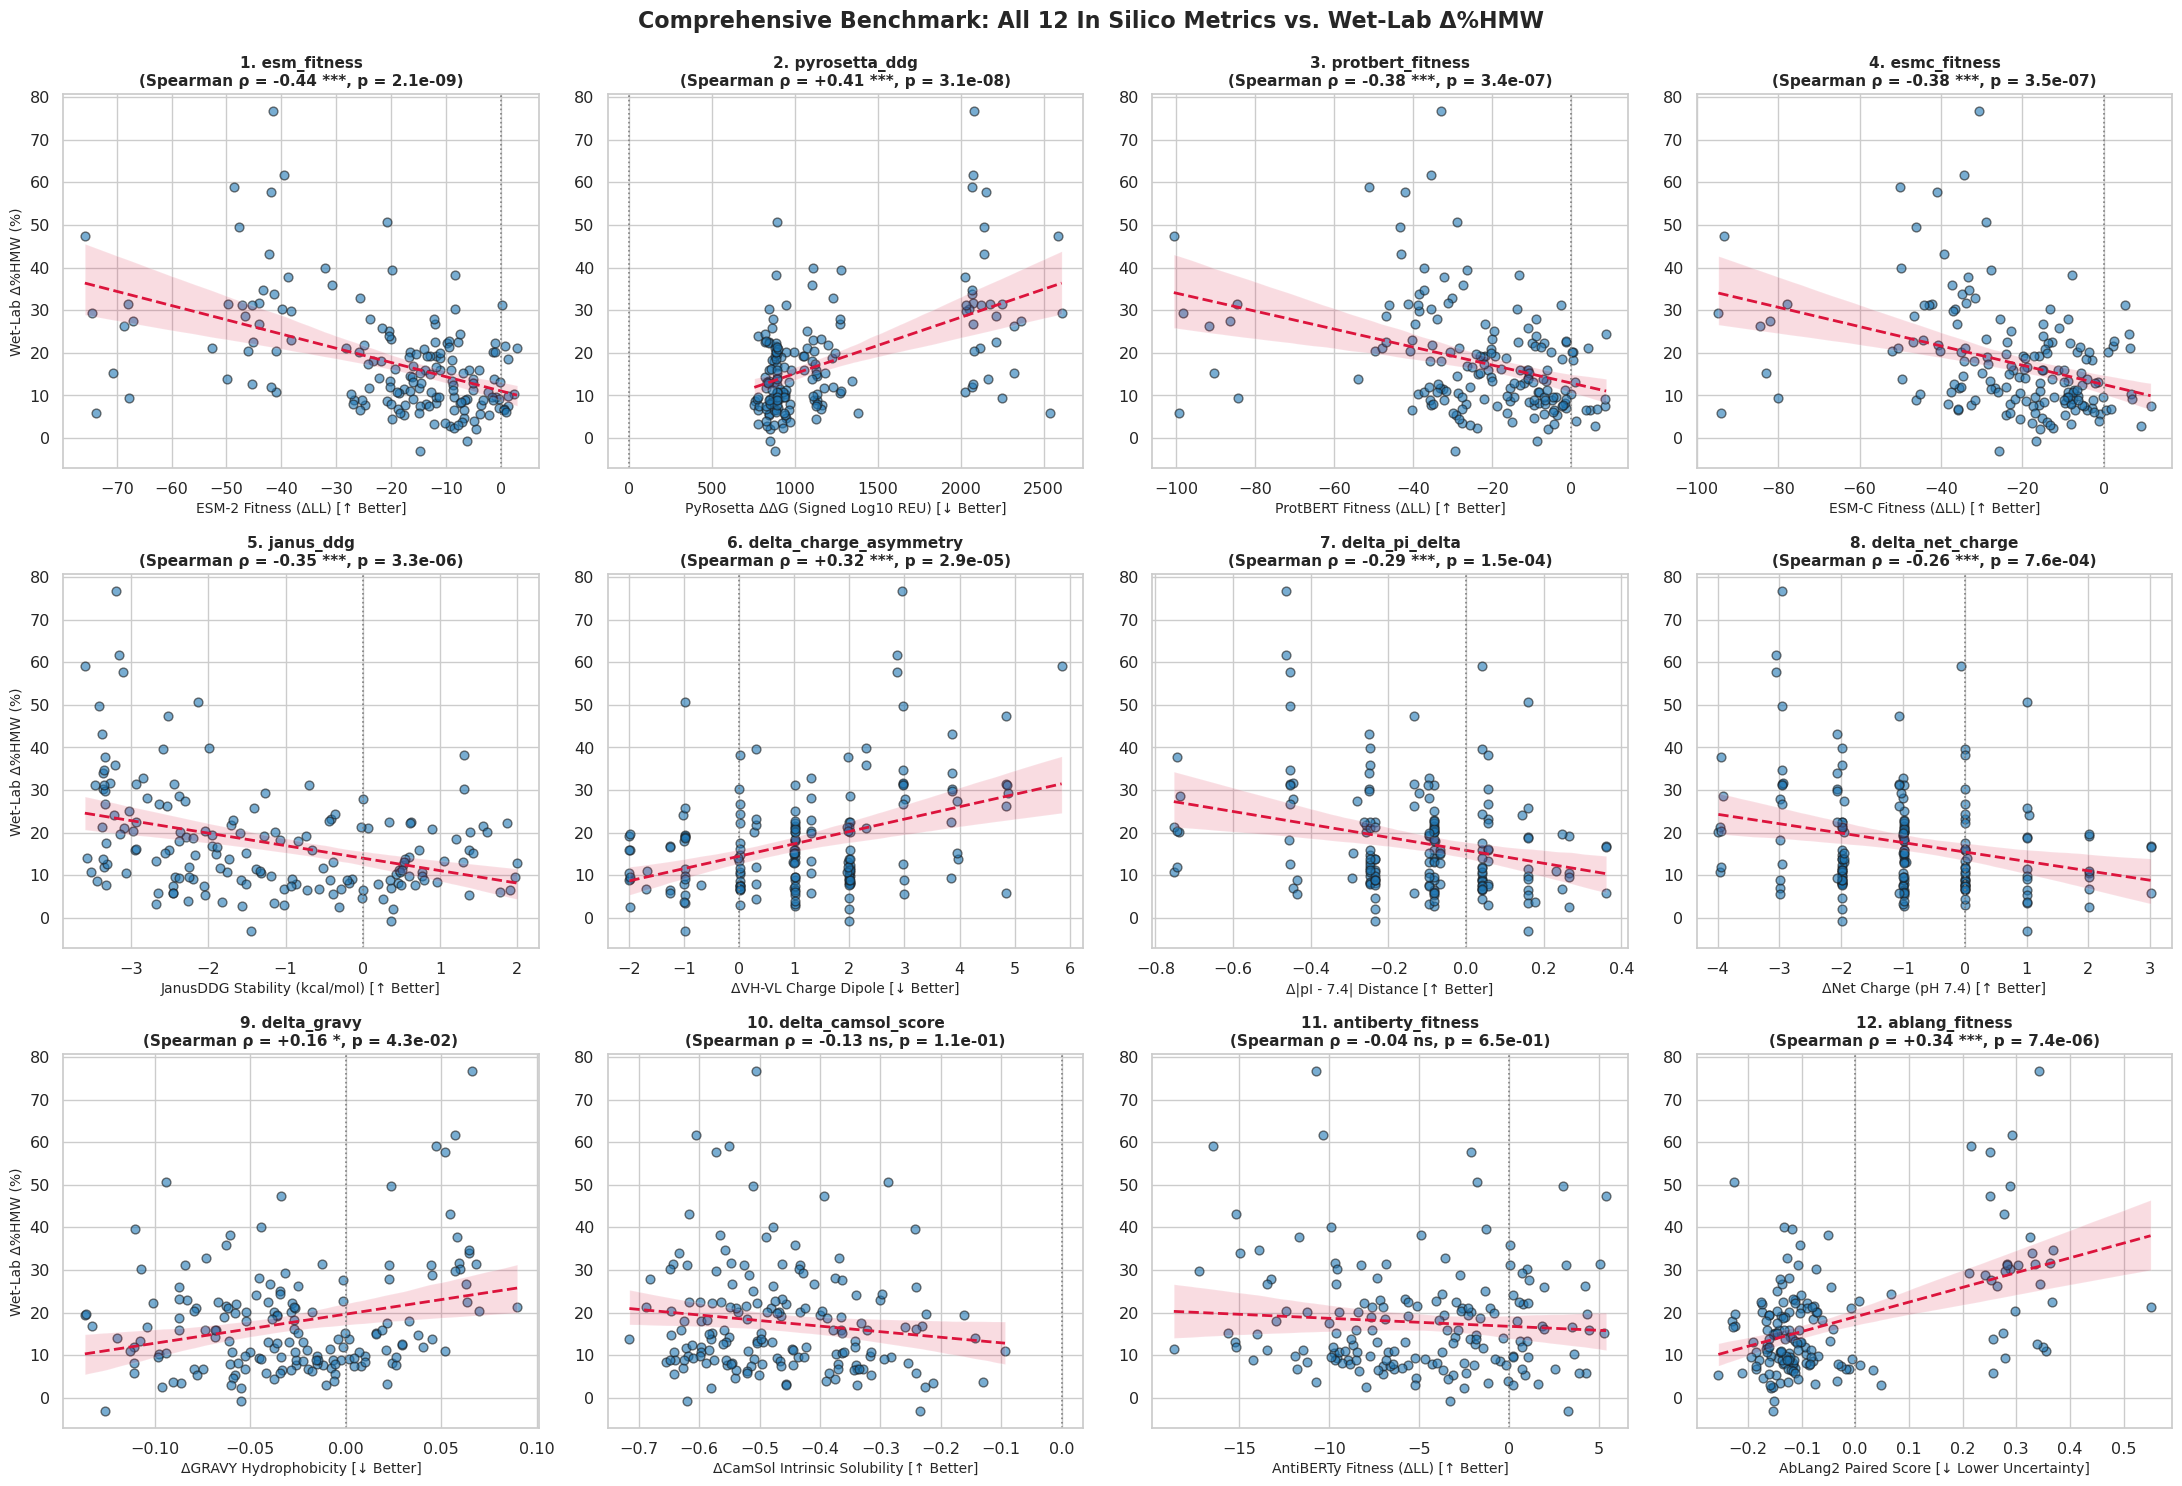

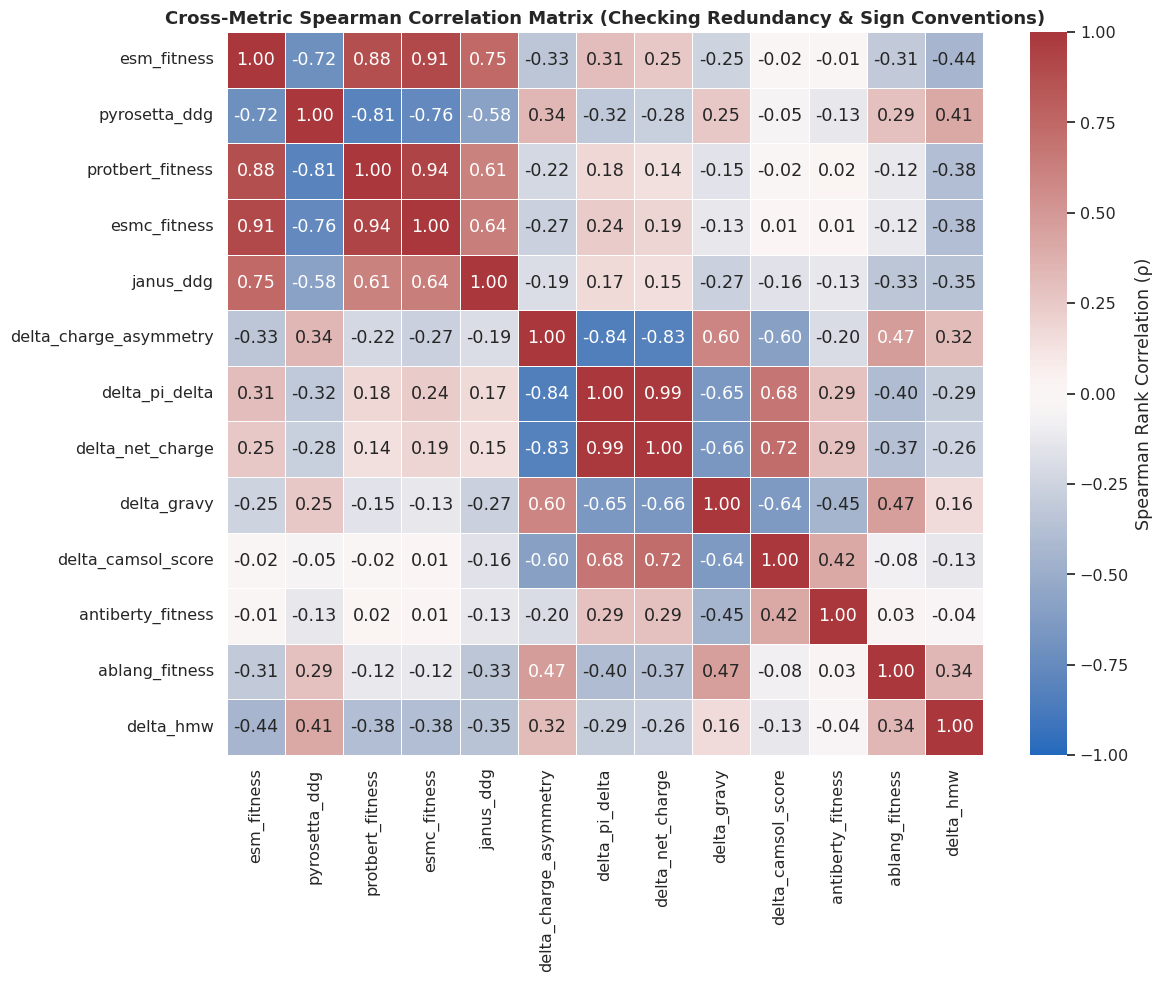

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

# 1. Define all 12 metrics for the 3x4 Scatter Grid
all_scatter_metrics = [
    ('esm_fitness',            'ESM-2 Fitness (ΔLL) [↑ Better]'),
    ('pyrosetta_ddg',          'PyRosetta ΔΔG (Signed Log10 REU) [↓ Better]'),
    ('protbert_fitness',       'ProtBERT Fitness (ΔLL) [↑ Better]'),
    ('esmc_fitness',           'ESM-C Fitness (ΔLL) [↑ Better]'),
    ('janus_ddg',              'JanusDDG Stability (kcal/mol) [↑ Better]'),
    ('delta_charge_asymmetry', 'ΔVH-VL Charge Dipole [↓ Better]'),
    ('delta_pi_delta',         'Δ|pI - 7.4| Distance [↑ Better]'),
    ('delta_net_charge',       'ΔNet Charge (pH 7.4) [↑ Better]'),
    ('delta_gravy',            'ΔGRAVY Hydrophobicity [↓ Better]'),
    ('delta_camsol_score',     'ΔCamSol Intrinsic Solubility [↑ Better]'),
    ('antiberty_fitness',      'AntiBERTy Fitness (ΔLL) [↑ Better]'),
    ('ablang_fitness',         'AbLang2 Paired Score [↓ Lower Uncertainty]')
]

# ==========================================
# FIGURE 1: 3x4 Grid of All 12 Metrics vs. Wet-Lab Δ%HMW
# ==========================================
fig, axes = plt.subplots(3, 4, figsize=(22, 15))
plt.subplots_adjust(hspace=0.40, wspace=0.28)
axes_flat = axes.flatten()

for idx, (col, label) in enumerate(all_scatter_metrics):
    ax = axes_flat[idx]
    if col not in mutants.columns:
        ax.set_visible(False)
        continue
        
    valid = mutants[[col, 'delta_hmw']].dropna()
    
    # Guard against constant columns
    if len(valid) <= 3 or valid[col].nunique() <= 1:
        ax.text(0.5, 0.5, f"{col}\n(Constant / No Variance)", ha='center', va='center', fontsize=12)
        ax.set_title(f"{idx+1}. {col} (Constant)", fontweight='bold', fontsize=11)
        continue

    rho, pval = spearmanr(valid[col], valid['delta_hmw'])
    stars = "***" if pval < 0.001 else ("**" if pval < 0.01 else ("*" if pval < 0.05 else "ns"))
    
    sns.regplot(
        data=valid, x=col, y='delta_hmw', ax=ax,
        scatter_kws={'alpha': 0.6, 'color': '#1f77b4', 'edgecolor': 'k', 's': 40},
        line_kws={'color': 'crimson', 'linestyle': '--', 'linewidth': 2}
    )
    
    ax.axvline(0, color='gray', linestyle=':', linewidth=1.2)
    ax.set_title(f"{idx+1}. {col}\n(Spearman ρ = {rho:+.2f} {stars}, p = {pval:.1e})", fontweight='bold', fontsize=11)
    ax.set_xlabel(label, fontsize=10)
    ax.set_ylabel("Wet-Lab Δ%HMW (%)" if idx % 4 == 0 else "", fontsize=10)

plt.suptitle("Comprehensive Benchmark: All 12 In Silico Metrics vs. Wet-Lab Δ%HMW", fontsize=16, fontweight='bold', y=0.99)
plt.tight_layout()
plt.savefig("all_metrics_scatter_grid.png", dpi=300)
plt.show()

# ==========================================
# FIGURE 2: Cross-Metric Spearman Correlation Heatmap
# ==========================================
heatmap_cols = [c for c, _ in all_scatter_metrics if c in mutants.columns and mutants[c].nunique() > 1] + ['delta_hmw']
corr_matrix = mutants[heatmap_cols].corr(method='spearman')

plt.figure(figsize=(12, 10))
sns.heatmap(
    corr_matrix, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1,
    linewidths=0.5, cbar_kws={"label": "Spearman Rank Correlation (ρ)"}
)
plt.title("Cross-Metric Spearman Correlation Matrix (Checking Redundancy & Sign Conventions)", fontweight='bold', fontsize=13)
plt.tight_layout()
plt.savefig("metrics_cross_correlation_heatmap.png", dpi=300)
plt.show()